In [1]:
import os
from astropy.io import fits
import numpy as np
import pandas as pd
import astropy.units as u
from astropy.coordinates import SkyCoord
import seaborn as sns
import matplotlib.pyplot as plt
import os
from tqdm import tqdm
from astropy.table import Table
%matplotlib inline

In [2]:
def arcsinh_rgb(imgs, bands, scales=None,m = 0.03):
    import numpy as np
    rgbscales =dict(g=(2,6.0), r=(1,3.4), z=(0,2.2))
    if scales is not None:
        rgbscales.update(scales)

    I = 0
    for img,band in zip(imgs, bands):
        plane,scale = rgbscales[band]
        img = np.maximum(0, img * scale + m)
        I = I + img
    I /= len(bands)

    Q = 50
    fI = np.arcsinh(Q * I) / np.sqrt(Q)
    # fI = MTF(I)
    I += (I == 0.) * 1e-9
    H,W = I.shape
    rgb = np.zeros((H,W,3), np.float32)
    for img,band in zip(imgs, bands):
        plane,scale = rgbscales[band]
        rgb[:,:,plane] = (img * scale + m) * fI / I
    rgb = np.clip(rgb, 0, 1)
    return rgb

1.8660551 0.0033001378 -0.0075286813


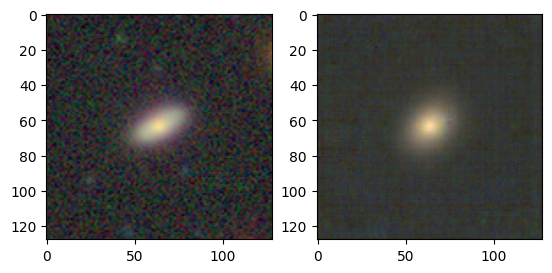

In [3]:
from astropy.io import fits
original = fits.open("/data/public/xqf/123/DESI1/images/12_original.fits")
generate = fits.open("/data/public/xqf/123/DESI1/images/12_generate.fits")
for i in range(generate[0].data.shape[0]):
    if i == 15:
        plt.subplot(121)
        plt.imshow(arcsinh_rgb(original[0].data[i,:,:,:], ["g","r","z"]))
        plt.subplot(122)
        g_img = generate[0].data[i,:,:,:]
        print(np.max(g_img), np.median(g_img), np.min(g_img))
        plt.imshow(arcsinh_rgb(generate[0].data[i,:,:,:], ["g","r","z"]))
        plt.show()

In [4]:
data_dir = "/data/public/xqf/123/DESI2/test_tractor/" # 需要跑tractor图像的文件夹，文件命名无要求，fits即可，路径下要求有且仅有图像。
# filelist = [data_dir + i for i in os.listdir(data_dir)] # 图像完整路径
sex_path = "/data1/public/BGS/sim_z/south/acss.sex" # tractor配置文件位置，这个如果跑DESI的就不用改。
catalog_path = "/data/public/xqf/123/DESI2/test_tractor_catalog/" # tractor输出的cat文件存放路径

In [5]:
cmd1 = f"cd {data_dir}"
# for filename in filelist[0:2]: # 循环跑sex，文件过多的话可以改成并行
for k in range(1,15):
  original = fits.open("/data/public/xqf/123/DESI1/images/" + str(k) + "_original.fits")
  generate = fits.open("/data/public/xqf/123/DESI1/images/" + str(k) + "_generate.fits")
  for i in range(generate[0].data.shape[0]):
      # if i <= 15:
        for j in range(2):
          if j == 0:
            img = generate[0].data[i,:,:,:]
            filename = data_dir + str(k) + "_" + str(i) + "gen.fits"
          else:
            img = original[0].data[i,:,:,:]
            filename = data_dir + str(k) + "_" +str(i) + "ori.fits"
          name = filename.split("/")[-1].split(".fits")[0] # 获取文件名本身
          
          # 读图分离通道，写到相同目录下，后面会删
          # img = fits.getdata(filename)
          g, r, z = img[0], img[1], img[2]
          fits.writeto(filename.replace(".fits", "_g.fits"), g, overwrite=True)
          fits.writeto(filename.replace(".fits", "_r.fits"), r, overwrite=True)
          fits.writeto(filename.replace(".fits", "_z.fits"), z, overwrite=True)
          
          for band in ["g", "r", "z"]:
            catalog_name = f"{catalog_path}{name}_{band}.cat"
            cmd = f"sex {filename.replace('.fits', f'_{band}.fits')} -c {sex_path} -CATALOG_NAME {catalog_name}"
            os.system(cmd1 + "&&" + cmd)
          os.system(f"rm -rf {filename.replace('.fits', '_g.fits')}")
          os.system(f"rm -rf {filename.replace('.fits', '_r.fits')}")
          os.system(f"rm -rf {filename.replace('.fits', '_z.fits')}")
          # os.system(f"rm -rf {data_dir}check.fits")
  

In [5]:
param_list = os.listdir(catalog_path) # 之前存放生成cat文件的地方
# 测量的参数名，从NUMBER起的参数名需要和配置文件sex_path中的PARAMETERS_NAME指向的.param文件中的输出参数一致。
params = ['cat_name', 'NUMBER', 'X_IMAGE', 'Y_IMAGE', 'MAG_BEST', 'MAGERR_BEST', 'FLUX_BEST', 'FLUXERR_BEST', 'MAG_AUTO', 'MAGERR_AUTO', 'MAG_ISOCOR', 'MAGERR_ISOCOR', 'A_IMAGE', 'ERRA_IMAGE', 'B_IMAGE', 'ERRB_IMAGE', 'THETA_IMAGE', 'ERRTHETA_IMAGE', 'ELONGATION', 'FLUX_RADIUS', 'FLUX_PETRO', 'FLUXERR_PETRO', 'PETRO_RADIUS', 'KRON_RADIUS', 'BACKGROUND', 'ELLIPTICITY', 'FWHM_IMAGE', 'MAG_PETRO', 'MU_MAX', 'MU_THRESHOLD']
g, r, z = pd.DataFrame(columns=params), pd.DataFrame(columns=params), pd.DataFrame(columns=params)
problem = []

for cax in tqdm((param_list)):
  for band in ["g","r","z"]:
    if f"{band}.cat" in cax:
      cat_name = cax[:-6]  # 去掉后缀获取文件名
      name = f"{catalog_path}{cax}"
      data = Table.read(filename=name, format='ascii.sextractor')
      if len(data) > 1:
          idx = np.argwhere((np.array(data['X_IMAGE']) > 62) & (np.array(data['X_IMAGE']) < 66) &
                            (np.array(data['Y_IMAGE']) > 62) & (np.array(data['Y_IMAGE']) < 66)) # 这里是为了找图中心所在的连通域，128的图像定义像素位置在x,y轴均在62,66的矩形中
          if idx.shape[0] == 0:
              problem.append(name)
          else:
              selected_df = data[idx[0]].to_pandas()
              selected_df['cat_name'] = cat_name
              selected_df['idd'] = cat_name[:-3]
              # 根据当前波段更新对应的DataFrame
              if band == 'g':
                  g = pd.concat([g, selected_df[params]], ignore_index=True)
              elif band == 'r':
                  r = pd.concat([r, selected_df[params]], ignore_index=True)
              elif band == 'z':
                  z = pd.concat([z, selected_df[params]], ignore_index=True)
              del selected_df

100%|██████████| 21504/21504 [01:37<00:00, 220.06it/s]


In [6]:
gr = pd.merge(g, r, how="inner", on=["cat_name"], suffixes=('_g', '_r'))
z_renamed = z.rename(columns=lambda x: x + '_z' if x not in ['cat_name'] else x)
grz = pd.merge(gr, z_renamed, how="inner", on=["cat_name"])

In [7]:
grz

,cat_name,NUMBER_g,X_IMAGE_g,Y_IMAGE_g,MAG_BEST_g,MAGERR_BEST_g,FLUX_BEST_g,FLUXERR_BEST_g,MAG_AUTO_g,MAGERR_AUTO_g,...,FLUX_PETRO_z,FLUXERR_PETRO_z,PETRO_RADIUS_z,KRON_RADIUS_z,BACKGROUND_z,ELLIPTICITY_z,FWHM_IMAGE_z,MAG_PETRO_z,MU_MAX_z,MU_THRESHOLD_z
0,12_78gen,1,64.8280,63.7566,17.9815,0.0724,64.18204,4.275961,17.9815,0.0724,...,203.46030,7.605712,4.62,3.50,0.004967,0.077,12.72,16.7288,19.6001,26.2632
1,12_28ori,3,64.4641,64.1664,17.7272,0.0593,81.11550,4.429149,16.6620,0.0420,...,360.41430,10.749540,6.60,6.12,0.007354,0.269,23.64,16.1080,20.8237,24.4297
2,11_107gen,1,64.5837,64.3535,17.7858,0.0614,76.85909,4.348855,17.7950,0.0621,...,328.50000,9.079827,3.96,3.50,0.005115,0.063,5.89,16.2087,18.0299,26.3535
3,7_146ori,1,64.4227,64.6914,17.7226,0.0589,81.46111,4.419704,17.7226,0.0589,...,307.21700,8.798743,4.62,3.50,0.001517,0.455,8.79,16.2814,18.4861,24.6238
4,1_140ori,1,65.2431,64.7989,18.9083,0.1052,27.33284,2.647461,18.9083,0.1052,...,156.90790,6.544960,5.28,3.50,0.001602,0.701,13.34,17.0109,19.5891,24.3236
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4992,13_127ori,1,64.5608,64.4364,14.4259,0.0144,1696.87400,22.563380,14.4259,0.0144,...,5950.90900,39.685570,5.28,3.50,0.017279,0.619,17.89,13.0635,17.0916,24.4582
4993,6_5ori,1,64.4661,64.0444,18.0796,0.0720,58.63564,3.887759,18.0796,0.0720,...,294.90750,8.574817,4.62,3.50,0.003745,0.146,5.98,16.3258,18.1476,24.4559
4994,10_193ori,1,64.3691,64.5290,17.1533,0.0469,137.62290,5.937280,17.1533,0.0469,...,480.60290,12.001660,5.94,3.50,0.008120,0.297,6.31,15.7955,18.1730,24.0997
4995,4_114gen,1,64.4605,64.3003,19.4246,0.1320,16.98882,2.064873,19.4246,0.1320,...,54.06197,3.700904,4.62,3.50,0.003983,0.120,12.67,18.1678,21.0635,26.7064


In [8]:
grz.columns

Index(['cat_name', 'NUMBER_g', 'X_IMAGE_g', 'Y_IMAGE_g', 'MAG_BEST_g',
       'MAGERR_BEST_g', 'FLUX_BEST_g', 'FLUXERR_BEST_g', 'MAG_AUTO_g',
       'MAGERR_AUTO_g', 'MAG_ISOCOR_g', 'MAGERR_ISOCOR_g', 'A_IMAGE_g',
       'ERRA_IMAGE_g', 'B_IMAGE_g', 'ERRB_IMAGE_g', 'THETA_IMAGE_g',
       'ERRTHETA_IMAGE_g', 'ELONGATION_g', 'FLUX_RADIUS_g', 'FLUX_PETRO_g',
       'FLUXERR_PETRO_g', 'PETRO_RADIUS_g', 'KRON_RADIUS_g', 'BACKGROUND_g',
       'ELLIPTICITY_g', 'FWHM_IMAGE_g', 'MAG_PETRO_g', 'MU_MAX_g',
       'MU_THRESHOLD_g', 'NUMBER_r', 'X_IMAGE_r', 'Y_IMAGE_r', 'MAG_BEST_r',
       'MAGERR_BEST_r', 'FLUX_BEST_r', 'FLUXERR_BEST_r', 'MAG_AUTO_r',
       'MAGERR_AUTO_r', 'MAG_ISOCOR_r', 'MAGERR_ISOCOR_r', 'A_IMAGE_r',
       'ERRA_IMAGE_r', 'B_IMAGE_r', 'ERRB_IMAGE_r', 'THETA_IMAGE_r',
       'ERRTHETA_IMAGE_r', 'ELONGATION_r', 'FLUX_RADIUS_r', 'FLUX_PETRO_r',
       'FLUXERR_PETRO_r', 'PETRO_RADIUS_r', 'KRON_RADIUS_r', 'BACKGROUND_r',
       'ELLIPTICITY_r', 'FWHM_IMAGE_r', 'MAG_PETRO_r', 

In [9]:
grz[['FLUX_RADIUS_g','FLUX_RADIUS_r','FLUX_RADIUS_z']]

,FLUX_RADIUS_g,FLUX_RADIUS_r,FLUX_RADIUS_z
0,9.751,9.405,9.404
1,61.445,60.764,28.551
2,7.330,6.752,6.259
3,8.752,7.678,6.884
4,11.938,10.457,9.424
...,...,...,...
4992,23.876,22.293,23.674
4993,7.413,6.960,6.308
4994,12.579,12.102,11.613
4995,8.781,8.587,8.614


In [10]:
flux = 22.5-np.log10(grz[['FLUX_RADIUS_g','FLUX_RADIUS_r','FLUX_RADIUS_z']])

In [11]:
np.array(flux.iloc[:,:1]) - np.array(flux.iloc[:,1:])

array([[-0.01569036, -0.01573654],
       [-0.00484019, -0.33286522],
       [-0.03567154, -0.06859902],
       ...,
       [-0.01678897, -0.03470169],
       [-0.00970251, -0.00833911],
       [-0.02896195, -0.01552414]])

In [12]:
grz_o = grz[grz['cat_name'].str.contains("ori")]
grz_o['cat_name1'] = grz_o['cat_name'].str.replace('ori','').apply(int)
grz_o.set_index(grz_o['cat_name1'])

/data/public/xqf/anaconda3/envs/xu/lib/python3.7/site-packages/ipykernel_launcher.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  


,cat_name,NUMBER_g,X_IMAGE_g,Y_IMAGE_g,MAG_BEST_g,MAGERR_BEST_g,FLUX_BEST_g,FLUXERR_BEST_g,MAG_AUTO_g,MAGERR_AUTO_g,...,FLUXERR_PETRO_z,PETRO_RADIUS_z,KRON_RADIUS_z,BACKGROUND_z,ELLIPTICITY_z,FWHM_IMAGE_z,MAG_PETRO_z,MU_MAX_z,MU_THRESHOLD_z,cat_name1
cat_name1,,,,,,,,,,,,,,,,,,,,,
1228,12_28ori,3,64.4641,64.1664,17.7272,0.0593,81.11550,4.429149,16.6620,0.0420,...,10.749540,6.60,6.12,0.007354,0.269,23.64,16.1080,20.8237,24.4297,1228
7146,7_146ori,1,64.4227,64.6914,17.7226,0.0589,81.46111,4.419704,17.7226,0.0589,...,8.798743,4.62,3.50,0.001517,0.455,8.79,16.2814,18.4861,24.6238,7146
1140,1_140ori,1,65.2431,64.7989,18.9083,0.1052,27.33284,2.647461,18.9083,0.1052,...,6.544960,5.28,3.50,0.001602,0.701,13.34,17.0109,19.5891,24.3236,1140
8129,8_129ori,1,64.4035,64.6262,16.6905,0.0389,210.76920,7.553407,16.6905,0.0389,...,15.946820,4.62,3.50,0.012736,0.160,8.51,14.9921,17.6246,24.1534,8129
6228,6_228ori,1,64.5180,64.7073,18.5252,0.0869,38.89693,3.111753,18.5252,0.0869,...,6.923603,4.62,3.50,0.002761,0.239,7.63,16.8314,18.9990,24.5308,6228
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
378,3_78ori,1,63.5781,64.4753,18.5733,0.0868,37.21203,2.975900,18.4203,0.0828,...,5.309567,5.94,3.50,0.000870,0.032,9.53,17.7024,20.3510,24.7186,378
13127,13_127ori,1,64.5608,64.4364,14.4259,0.0144,1696.87400,22.563380,14.4259,0.0144,...,39.685570,5.28,3.50,0.017279,0.619,17.89,13.0635,17.0916,24.4582,13127
65,6_5ori,1,64.4661,64.0444,18.0796,0.0720,58.63564,3.887759,18.0796,0.0720,...,8.574817,4.62,3.50,0.003745,0.146,5.98,16.3258,18.1476,24.4559,65


In [13]:
grz_g = grz[grz['cat_name'].str.contains("gen")]
grz_g['cat_name1'] = grz_g['cat_name'].str.replace('gen','').apply(int)
grz_g.set_index('cat_name1')

/data/public/xqf/anaconda3/envs/xu/lib/python3.7/site-packages/ipykernel_launcher.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  


,cat_name,NUMBER_g,X_IMAGE_g,Y_IMAGE_g,MAG_BEST_g,MAGERR_BEST_g,FLUX_BEST_g,FLUXERR_BEST_g,MAG_AUTO_g,MAGERR_AUTO_g,...,FLUX_PETRO_z,FLUXERR_PETRO_z,PETRO_RADIUS_z,KRON_RADIUS_z,BACKGROUND_z,ELLIPTICITY_z,FWHM_IMAGE_z,MAG_PETRO_z,MU_MAX_z,MU_THRESHOLD_z
cat_name1,,,,,,,,,,,,,,,,,,,,,
1278,12_78gen,1,64.8280,63.7566,17.9815,0.0724,64.18204,4.275961,17.9815,0.0724,...,203.46030,7.605712,4.62,3.5,0.004967,0.077,12.72,16.7288,19.6001,26.2632
11107,11_107gen,1,64.5837,64.3535,17.7858,0.0614,76.85909,4.348855,17.7950,0.0621,...,328.50000,9.079827,3.96,3.5,0.005115,0.063,5.89,16.2087,18.0299,26.3535
14238,14_238gen,1,64.4531,64.4215,19.1280,0.1147,22.32487,2.357863,19.1280,0.1147,...,108.76280,5.330591,3.96,3.5,0.004456,0.076,5.49,17.4088,18.9232,26.6915
148,1_48gen,1,65.0663,64.2116,18.2615,0.0752,49.59174,3.434568,18.0876,0.0698,...,46.35254,3.285954,3.50,3.5,0.007578,0.499,7.44,18.3348,18.8086,26.3472
1451,14_51gen,1,64.3628,64.0610,16.4216,0.0327,269.98530,8.140331,16.4216,0.0327,...,1027.38400,16.659020,4.62,3.5,0.010934,0.241,8.93,14.9707,17.6316,27.0899
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
981,9_81gen,1,65.5266,64.5174,18.8357,0.1268,29.22274,3.412278,18.8357,0.1268,...,87.08569,7.698698,5.28,3.5,0.005189,0.102,10.33,17.6501,20.3331,26.6199
5171,5_171gen,1,64.3372,64.5043,17.5245,0.0551,97.77113,4.963891,17.5245,0.0551,...,411.15010,9.971511,4.62,3.5,0.004825,0.101,7.16,15.9650,18.2186,26.5212
535,5_35gen,1,64.2519,64.4146,18.7214,0.0957,32.46827,2.861695,18.7214,0.0957,...,129.84160,5.693849,3.96,3.5,0.004359,0.098,8.20,17.2165,19.3971,26.5938


In [14]:
aa = pd.merge(grz_o, grz_g, how="inner", on=["cat_name1"])

In [15]:
aa

,cat_name_x,NUMBER_g_x,X_IMAGE_g_x,Y_IMAGE_g_x,MAG_BEST_g_x,MAGERR_BEST_g_x,FLUX_BEST_g_x,FLUXERR_BEST_g_x,MAG_AUTO_g_x,MAGERR_AUTO_g_x,...,FLUX_PETRO_z_y,FLUXERR_PETRO_z_y,PETRO_RADIUS_z_y,KRON_RADIUS_z_y,BACKGROUND_z_y,ELLIPTICITY_z_y,FWHM_IMAGE_z_y,MAG_PETRO_z_y,MU_MAX_z_y,MU_THRESHOLD_z_y
0,12_28ori,3,64.4641,64.1664,17.7272,0.0593,81.11550,4.429149,16.6620,0.0420,...,362.52390,9.528784,3.96,3.5,0.005172,0.109,7.62,16.1017,18.4174,26.2563
1,12_28ori,3,64.4641,64.1664,17.7272,0.0593,81.11550,4.429149,16.6620,0.0420,...,96.38781,5.365274,5.28,3.5,0.009976,0.211,13.34,17.5399,20.7014,25.4990
2,1_228ori,1,64.4281,64.1853,17.7566,0.0626,78.95332,4.549555,17.7566,0.0626,...,362.52390,9.528784,3.96,3.5,0.005172,0.109,7.62,16.1017,18.4174,26.2563
3,1_228ori,1,64.4281,64.1853,17.7566,0.0626,78.95332,4.549555,17.7566,0.0626,...,96.38781,5.365274,5.28,3.5,0.009976,0.211,13.34,17.5399,20.7014,25.4990
4,1_140ori,1,65.2431,64.7989,18.9083,0.1052,27.33284,2.647461,18.9083,0.1052,...,157.91590,6.657087,3.96,3.5,0.004488,0.216,7.02,17.0039,18.9425,26.6374
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1972,9_115ori,1,64.3878,64.3336,17.7894,0.0659,76.60420,4.647870,17.7894,0.0659,...,186.57240,7.363840,4.62,3.5,0.007114,0.185,14.17,16.8229,19.6508,26.0764
1973,4_183ori,2,64.3564,64.7425,17.9704,0.0686,64.84055,4.094664,17.9704,0.0686,...,84.66161,4.799307,4.62,3.5,0.004199,0.176,10.41,17.6808,20.3561,26.6867
1974,3_78ori,1,63.5781,64.4753,18.5733,0.0868,37.21203,2.975900,18.4203,0.0828,...,63.95460,3.979089,4.62,3.5,0.004258,0.143,11.70,17.9853,20.7445,26.6831
1975,13_127ori,1,64.5608,64.4364,14.4259,0.0144,1696.87400,22.563380,14.4259,0.0144,...,5542.56700,41.633340,5.28,3.5,0.022124,0.631,18.83,13.1407,17.1640,25.4006


In [16]:
aa[['FLUX_RADIUS_g_x','FLUX_RADIUS_r_x','FLUX_RADIUS_z_x','FLUX_RADIUS_g_y','FLUX_RADIUS_r_y','FLUX_RADIUS_z_y']]

,FLUX_RADIUS_g_x,FLUX_RADIUS_r_x,FLUX_RADIUS_z_x,FLUX_RADIUS_g_y,FLUX_RADIUS_r_y,FLUX_RADIUS_z_y
0,61.445,60.764,28.551,8.765,8.209,7.870
1,61.445,60.764,28.551,9.285,9.869,10.674
2,8.644,8.818,8.146,8.765,8.209,7.870
3,8.644,8.818,8.146,9.285,9.869,10.674
4,11.938,10.457,9.424,6.953,6.326,6.078
...,...,...,...,...,...,...
1972,8.240,8.824,7.945,8.482,8.385,8.453
1973,12.784,12.234,11.203,9.506,9.102,9.062
1974,13.739,13.201,12.238,8.737,8.539,8.758
1975,23.876,22.293,23.674,19.190,20.577,22.992


In [22]:
flux_o = 22.5-np.log10(aa[['FLUX_RADIUS_g_x','FLUX_RADIUS_r_x','FLUX_RADIUS_z_x']])
flux_g = 22.5-np.log10(aa[['FLUX_RADIUS_g_y','FLUX_RADIUS_r_y','FLUX_RADIUS_z_y']])

In [18]:
flux_o = aa[['FLUX_RADIUS_g_x','FLUX_RADIUS_r_x','FLUX_RADIUS_z_x']]
flux_g = aa[['FLUX_RADIUS_g_y','FLUX_RADIUS_r_y','FLUX_RADIUS_z_y']]

In [23]:
color_o = np.array(flux_o.iloc[:,:1]) - np.array(flux_o.iloc[:,1:])
color_g = np.array(flux_g.iloc[:,:1]) - np.array(flux_g.iloc[:,1:])
# color_o = np.array(flux_o)
# color_g = np.array(flux_g)

In [26]:
flux_o = 22.5-np.log10(aa[['FLUX_RADIUS_g_x','FLUX_RADIUS_r_x','FLUX_RADIUS_z_x']])
flux_g = 22.5-np.log10(aa[['FLUX_RADIUS_g_y','FLUX_RADIUS_r_y','FLUX_RADIUS_z_y']])
color_o = pd.DataFrame(np.array(flux_o.iloc[:,:1]) - np.array(flux_o.iloc[:,1:]))
color_g = pd.DataFrame(np.array(flux_g.iloc[:,:1]) - np.array(flux_g.iloc[:,1:]))

In [27]:
color_g

,0,1
0,-0.028462,-0.046777
1,0.026491,0.060545
2,-0.028462,-0.046777
3,0.026491,0.060545
4,-0.041043,-0.058412
...,...,...
1972,-0.004995,-0.001487
1973,-0.018861,-0.020774
1974,-0.009955,0.001043
1975,0.030307,0.078502


In [35]:
flux_cha = pd.DataFrame(np.array(flux_o) - np.array(flux_g))

In [36]:
flux_cha

,0,1,2
0,-0.845735,-0.869356,-0.559647
1,-0.820705,-0.789373,-0.427294
2,0.006037,-0.031080,-0.014970
3,0.031067,0.048903,0.117383
4,-0.234759,-0.218278,-0.190475
...,...,...,...
1972,0.012571,-0.022162,0.026917
1973,-0.128669,-0.128432,-0.092110
1974,-0.196593,-0.189200,-0.145306
1975,-0.094887,-0.034786,-0.012695


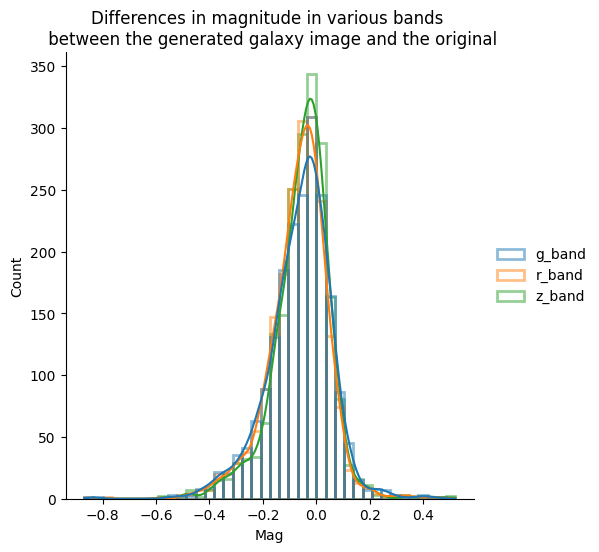

In [58]:
# sns.distplot(flux_cha.iloc[:,0], bins = 60, kde = True, hist_kws = {'color':'steelblue'}, kde_kws = {'color':'steelblue'}, norm_hist=True, label = 'g_band')
# sns.distplot(flux_cha.iloc[:,1], bins = 60, kde = True, hist_kws = {'color':'purple'}, kde_kws = {'color':'purple'}, norm_hist=True, label = 'r_band')
# sns.distplot(flux_cha.iloc[:,2], bins = 60, kde = True, hist_kws = {'color':'grey'}, kde_kws = {'color':'grey'}, norm_hist=True, label = 'z_band')
# sns.displot(flux_cha.iloc[:,0], bins = 40, kde = True, color = 'steelblue', label = 'g_band')
# sns.displot(flux_cha.iloc[:,1], bins = 40, kde = True, color = 'purple', label = 'r_band')
# sns.displot(flux_cha.iloc[:,2], bins = 40, kde = True, color = 'grey', label = 'z_band')
flux_cha.columns = ['g_band', 'r_band', 'z_band']
sns.displot(flux_cha, alpha = 0.5, bins = 40, kde = True, fill=False, linewidth=2)#, color = {'steelblue', 'purple', 'grey'})
# plt.legend()
plt.title('Differences in magnitude in various bands \n between the generated galaxy image and the original')
plt.xlabel('Mag')
plt.show()

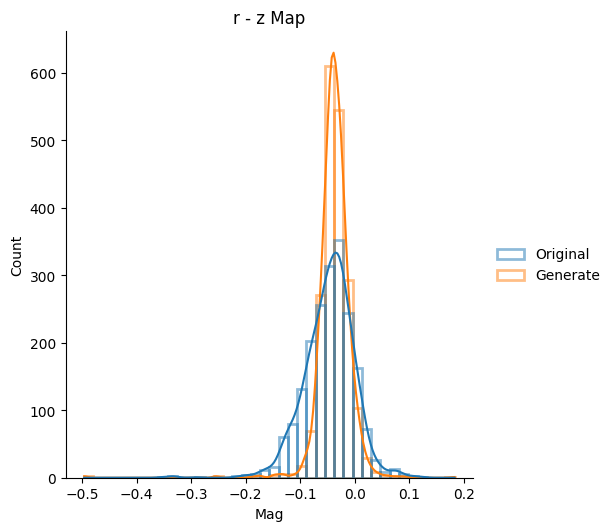

In [67]:
colors = pd.DataFrame([color_o.iloc[:,1],color_g.iloc[:,1]])
colors = colors.T
colors.columns = ['Original', 'Generate']
sns.displot(colors, alpha = 0.5, bins = 40, kde = True, fill=False, linewidth=2)#, color = {'steelblue', 'purple', 'grey'})
# plt.legend()
plt.title('r - z Map')
plt.xlabel('Mag')
plt.show()